# Gráficos del EDA (Certamen 2)

Tasas = hospitalizaciones (sin CMA, cohorte constante de 65 hospitales) / beneficiarios FONASA × 100.000.
Datos generados por `Procesamiento/limpieza_basica_GRD.ipynb`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

LIMPIO = '../GRD_CIE_TM/GRD_limpio/'

grd = pd.read_parquet(LIMPIO + 'grd_respiratorio_2019_2024.parquet')
hosp = grd[grd['ES_HOSPITALIZACION']]
nacional = pd.read_csv(LIMPIO + 'tasas_nacional.csv', index_col='ANIO')
edad = pd.read_csv(LIMPIO + 'tasas_tramo_edad.csv', index_col='TRAMO_EDAD')
diag = pd.read_csv(LIMPIO + 'tasas_grupo_diagnostico.csv', index_col='GRUPO_DIAGNOSTICO')
region = pd.read_csv(LIMPIO + 'tasas_region.csv')

## 1. Tasa nacional anual

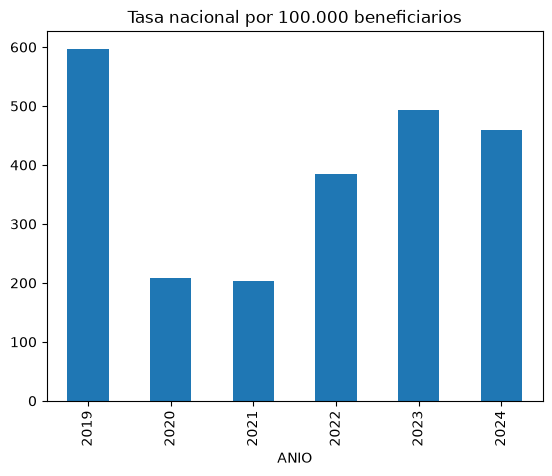

In [2]:
nacional['tasa_x100mil'].plot.bar(title='Tasa nacional por 100.000 beneficiarios')
plt.show()

## 2. Hospitalizaciones por año y mes

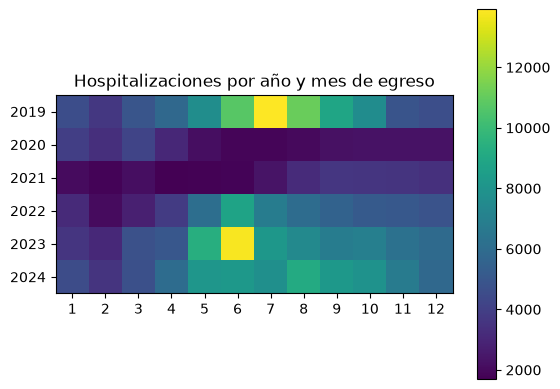

In [3]:
tabla = hosp.groupby(['ANIO', 'MES_ALTA']).size().unstack()
plt.imshow(tabla)
plt.colorbar()
plt.yticks(range(len(tabla)), tabla.index)
plt.xticks(range(12), tabla.columns)
plt.title('Hospitalizaciones por año y mes de egreso')
plt.show()

## 3. Tasa por tramo de edad

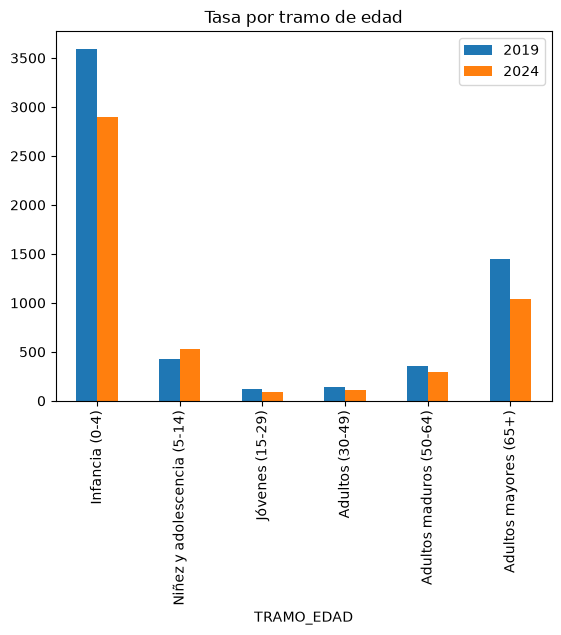

In [4]:
edad[['2019', '2024']].plot.bar(title='Tasa por tramo de edad')
plt.show()

## 4. Tasa por grupo diagnóstico

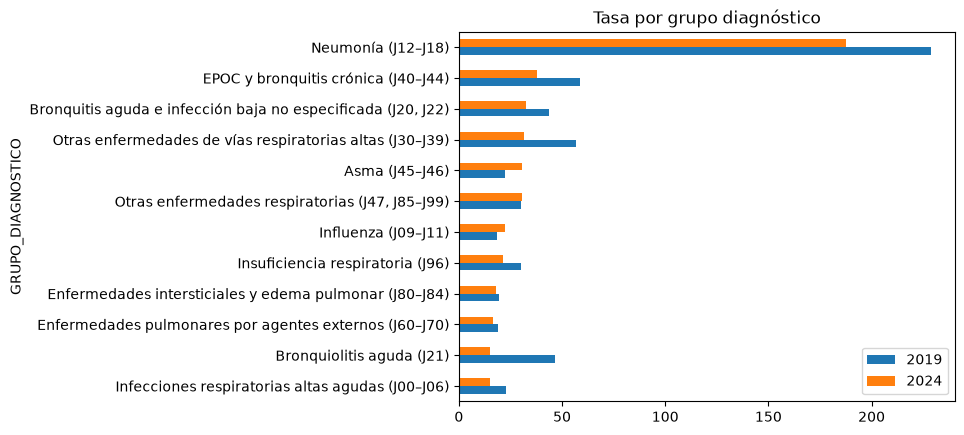

In [5]:
diag[['2019', '2024']].sort_values('2024').plot.barh(title='Tasa por grupo diagnóstico')
plt.show()

## 5. Tasa por región (2024)

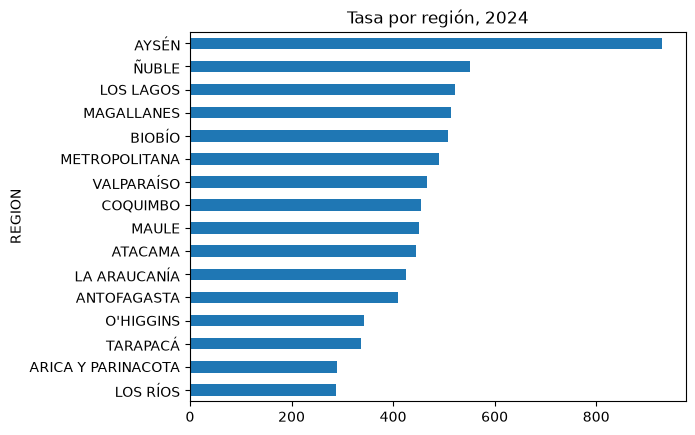

In [6]:
region[region['ANIO'] == 2024].set_index('REGION')['tasa_x100mil'].sort_values().plot.barh(title='Tasa por región, 2024')
plt.show()